# DS3000 Project - Lab Section 5, Group 04, Dataset #16

## Stage 1: Data Understanding and Baselines

Dataset: Plant Leaf Diseases

Proposed objective: Predict the plant/disease category of a leaf image using supervised multiclass image classification. Each observation is one image containing exactly one distinct annotated category. Images with no label or with multiple distinct categories are excluded.

### Dataset and prediction task

We use version 10 of the Plant Leaf Diseases dataset from Roboflow Universe, downloaded in COCO JSON format. The dataset contains images and annotations identifying plant and disease categories.

Our task is supervised multiclass classification. One observation is one retained image, and the target is the single distinct category assigned to that image’s annotations. Category IDs represent class names rather than numerical quantities, so the target has no physical measurement unit.

Although the original dataset includes bounding boxes for object detection, our current approach classifies whole images. We retain images containing exactly one distinct annotated category. An image may contain several leaves as long as their annotations all belong to the same category.

In [3]:
import json
from pathlib import Path

data_folder = Path("data/plant_leaf_diseases")

def load_annotations(split):
    with open(data_folder / split / "_annotations.coco.json") as f:
        return json.load(f)

train_annotations = load_annotations("train")
valid_annotations = load_annotations("valid")
test_annotations = load_annotations("test")

# Load each split's COC annotations into a dictionary

print("Training images:", len(train_annotations["images"]))
print("Validation images:", len(valid_annotations["images"]))
print("Test images:", len(test_annotations["images"]))
print("Annotations:", len(train_annotations["annotations"]))

#categories definitions are identical in all splits.
for category in train_annotations["categories"]:
    print(category["id"], " ", category["name"])

Training images: 3426
Validation images: 428
Test images: 428
Annotations: 11885
0   leaves
1   Apple Scab Leaf
2   Apple leaf
3   Apple rust leaf
4   Bell_pepper leaf
5   Bell_pepper leaf spot
6   Blueberry leaf
7   Cherry leaf
8   Corn Gray leaf spot
9   Corn leaf blight
10   Corn rust leaf
11   Peach leaf
12   Potato leaf
13   Potato leaf early blight
14   Potato leaf late blight
15   Raspberry leaf
16   Soyabean leaf
17   Soybean leaf
18   Squash Powdery mildew leaf
19   Strawberry leaf
20   Tomato Early blight leaf
21   Tomato Septoria leaf spot
22   Tomato leaf
23   Tomato leaf bacterial spot
24   Tomato leaf late blight
25   Tomato leaf mosaic virus
26   Tomato leaf yellow virus
27   Tomato mold leaf
28   Tomato two spotted spider mites leaf
29   grape leaf
30   grape leaf black rot


### Data cleaning and missingness

We load the image records, annotations, and category definitions separately for the training, validation, and test sets. Each image is linked to its annotated categories using its image ID.

We standardize the labels “Soybean leaf” and “Soyabean leaf” as one soybean category by mapping category ID 17 to ID 16 in every split. This prevents spelling variants of the same intended category from being treated as separate prediction targets.

We exclude images with no annotated category because they do not provide a target label. We also exclude images with multiple distinct categories because our current task requires one target category per image. These exclusions limit our analysis to images suitable for single-label classification.

We check whether every referenced image file exists and whether Pillow can fully load it. Missing or unreadable images are excluded from the retained image-label dictionaries. These operations exclude observations from the analysis without deleting the original image files or modifying the source annotations.

The printed outputs report the category-filtered counts and the missing/corrupt-image counts for each split. We exclude images with unavailable labels rather than guessing replacement labels.

In [4]:
# Store the unique categories found in each image


def get_image_labels(annotations):
    image_labels = {}
    for image in annotations["images"]:
        image_id = image["id"]
        image_labels[image_id] = set()

    for annotation in annotations["annotations"]:
        image_id = annotation["image_id"]
        category_id = annotation["category_id"]

        if category_id == 17:
            category_id = 16  #merge two soya beans together

        image_labels[image_id].add(category_id)
    return image_labels

test_image_labels = get_image_labels(test_annotations)
valid_image_labels = get_image_labels(valid_annotations)
train_image_labels = get_image_labels(train_annotations)


# Count images by how many different categories they contain
def print_image_label_stats(image_labels):
    print("No category:", 
          sum(len(labels) == 0 for labels in image_labels.values()))

    print("Exactly one category:",
          sum(len(labels) == 1 for labels in image_labels.values()))

    print("Multiple categories:",
          sum(len(labels) > 1 for labels in image_labels.values()))
print_image_label_stats(test_image_labels)
print_image_label_stats(valid_image_labels)
print_image_label_stats(train_image_labels)

No category: 1
Exactly one category: 425
Multiple categories: 2
No category: 2
Exactly one category: 422
Multiple categories: 4
No category: 16
Exactly one category: 3384
Multiple categories: 26


### Existing data split

The downloaded dataset provides training, validation, and test sets with an approximately 80/10/10 split. We preserve these assignments and apply the same cleaning rules to each split. Excluding unsuitable images changes the retained counts and may slightly change the percentages. Final retained counts are reported after cleaning and duplicate checking.

In [5]:
# Keep only images with exactly one distinct category

def filter_single_category_images(image_labels):
    single_category_labels = {}
    excluded_ids = []
    for image_id, labels in image_labels.items():
        if len(labels) == 1:
            single_category_labels[image_id] = labels
        else:
            excluded_ids.append(image_id)
    return single_category_labels, excluded_ids


train_single_category_labels, train_excluded_ids = filter_single_category_images(train_image_labels)
test_single_category_labels, test_excluded_ids = filter_single_category_images(test_image_labels)
valid_single_category_labels, valid_excluded_ids = filter_single_category_images(valid_image_labels)

print("Training images with a single category:", len(train_single_category_labels))
print("Validation images with a single category:", len(valid_single_category_labels))
print("Test images with a single category:", len(test_single_category_labels))


# checking for corrupt or missing images
from PIL import Image

def check_images(name, annotations, data_folder):
    missing_image_ids = []
    corrupt_image_ids = []
    for image in annotations["images"]:
        image_id = image["id"]
        image_path = data_folder / name / image["file_name"]

        if not image_path.is_file():
            missing_image_ids.append(image_id)
            continue

        try:
            with Image.open(image_path) as img:
                img.load()

        except (OSError, ValueError):
            corrupt_image_ids.append(image_id)
    return missing_image_ids, corrupt_image_ids

train_missing_image_ids, train_corrupt_image_ids = check_images("train", train_annotations, data_folder)
test_missing_image_ids, test_corrupt_image_ids = check_images("test", test_annotations, data_folder)
valid_missing_image_ids, valid_corrupt_image_ids = check_images("valid", valid_annotations, data_folder)


print("Training missing images:", len(train_missing_image_ids))
print("Training corrupt images:", len(train_corrupt_image_ids))
print("Validation missing images:", len(valid_missing_image_ids))
print("Validation corrupt images:", len(valid_corrupt_image_ids))
print("Test missing images:", len(test_missing_image_ids))
print("Test corrupt images:", len(test_corrupt_image_ids))


#get rid of corrupt and missing images
for image_id in train_missing_image_ids + train_corrupt_image_ids:
    train_single_category_labels.pop(image_id, None)

for image_id in valid_missing_image_ids + valid_corrupt_image_ids:
    valid_single_category_labels.pop(image_id, None)

for image_id in test_missing_image_ids + test_corrupt_image_ids:
    test_single_category_labels.pop(image_id, None)

print("Final training images:", len(train_single_category_labels))
print("Final validation images:", len(valid_single_category_labels))
print("Final test images:", len(test_single_category_labels))

Training images with a single category: 3384
Validation images with a single category: 422
Test images with a single category: 425
Training missing images: 24
Training corrupt images: 0
Validation missing images: 4
Validation corrupt images: 0
Test missing images: 1
Test corrupt images: 0
Final training images: 3360
Final validation images: 418
Final test images: 424


In [6]:
import hashlib
from PIL import Image

splits = {
    "test": (test_annotations, test_single_category_labels),
    "valid": (valid_annotations, valid_single_category_labels),
    "train": (train_annotations, train_single_category_labels),
}

seen_images = {}
duplicates = []
conflicting_labels = []

# Check test first, then validation, then training.
# For overlaps, keep the evaluation example and exclude its training copy.
for split, (annotations, retained_labels) in splits.items():
    for image in sorted(annotations["images"], key=lambda item: item["id"]):
        image_id = image["id"]

        if image_id not in retained_labels:
            continue

        image_path = data_folder / split / image["file_name"]

        with Image.open(image_path) as img:
            rgb = img.convert("RGB")
            signature = hashlib.sha256(
                str(rgb.size).encode() + rgb.tobytes()
            ).hexdigest()

        category_id = next(iter(retained_labels[image_id]))

        if signature in seen_images:
            previous_split, previous_id, previous_category = seen_images[signature]

            duplicates.append(
                (split, image_id, previous_split, previous_id)
            )

            if category_id != previous_category:
                conflicting_labels.append(
                    (split, image_id, previous_split, previous_id)
                )
        else:
            seen_images[signature] = (split, image_id, category_id)

print("Duplicate copies found:", len(duplicates))
print("Duplicates with conflicting labels:", len(conflicting_labels))

# Resolve inconsistent labels before automatically excluding duplicates.
if conflicting_labels:
    print("Conflicting image pairs:", conflicting_labels)
    raise ValueError("Review conflicting duplicate labels before continuing.")

for split, image_id, previous_split, previous_id in duplicates:
    splits[split][1].pop(image_id, None)

for split, (_, retained_labels) in splits.items():
    removed = sum(item[0] == split for item in duplicates)
    print(
        f"{split}: removed {removed} duplicate copies; "
        f"{len(retained_labels)} images retained"
    )

Duplicate copies found: 0
Duplicates with conflicting labels: 0
test: removed 0 duplicate copies; 424 images retained
valid: removed 0 duplicate copies; 418 images retained
train: removed 0 duplicate copies; 3360 images retained


### Duplicate handling and retained observations

We check retained images for exact duplicate pixel content by converting each image to RGB and hashing its dimensions and pixel values. This allows identical decoded images to be detected even when their filenames differ.

For matching images with consistent labels, we retain one copy. We process test images first, followed by validation and training images, so an exact copy found in an evaluation set is excluded from training. Conflicting labels trigger an error for review before duplicate exclusion proceeds.

The outputs above show the duplicate copies excluded and the final retained counts for each split. All later plots and model inputs use these cleaned image-label dictionaries.

This check identifies exact pixel duplicates. It does not detect all related images, such as crops or brightness-adjusted versions of the same original.

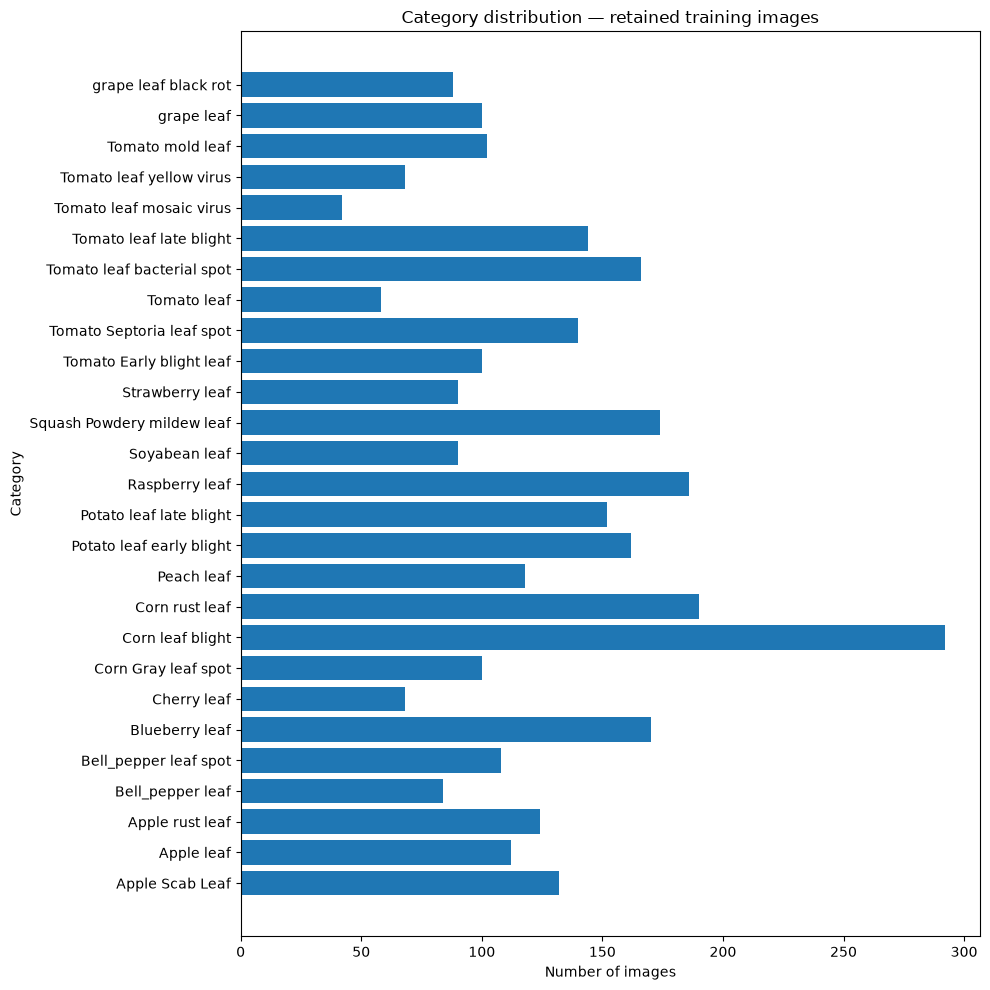

In [7]:
import matplotlib.pyplot as plt

category_counts = {}

for labels in train_single_category_labels.values():
    category_id = list(labels)[0]
    category_counts[category_id] = category_counts.get(category_id, 0) + 1

names = []
counts = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in category_counts:
        names.append(category["name"])
        counts.append(category_counts[category_id])

plt.figure(figsize=(10, 10))
plt.barh(names, counts)
plt.xlabel("Number of images")
plt.ylabel("Category")
plt.title("Category distribution — retained training images")
plt.tight_layout()
plt.show()

### Figure 1: Category Distribution of Retained Training Images

This figure counts retained training images in each category after cleaning and duplicate exclusion. Each image contributes once to its category’s count.

The distribution helps assess how much training evidence is available for each category. Categories with fewer examples may be harder to learn reliably, while categories with more examples can have greater influence on overall accuracy.

The training categories are unevenly represented. Corn leaf blight has considerably more images than other categories, while Tomato leaf mosaic virus has relatively few. This means the classifiers will have more training examples available for some categories than others.

This imbalance could lead to stronger performance on common categories and weaker performance on less represented ones. Overall accuracy could hide these differences, so we will also examine per-class results and macro-F1, which gives each category equal weight.

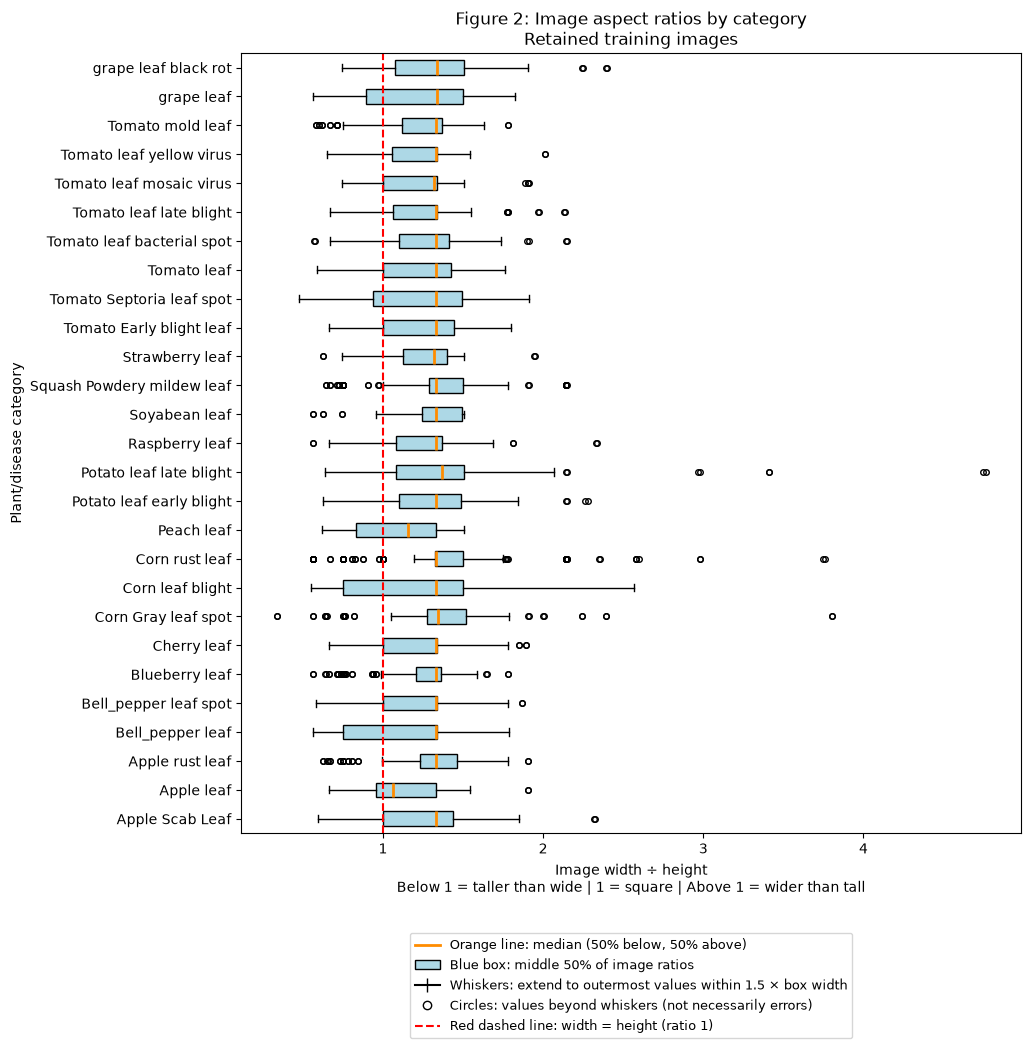

In [8]:
from PIL import Image
import matplotlib.pyplot as plt

aspect_ratios = {}

for image in train_annotations["images"]:
    image_id = image["id"]

    # Only use images retained after cleaning and duplicate removal.
    if image_id not in train_single_category_labels:
        continue

    category_id = next(iter(train_single_category_labels[image_id]))
    image_path = data_folder / "train" / image["file_name"]

    with Image.open(image_path) as img:
        width, height = img.size

    aspect_ratios.setdefault(category_id, []).append(width / height)

# Match category names to their measurements.
category_names = []
ratio_groups = []

for category in train_annotations["categories"]:
    category_id = category["id"]

    if category_id in aspect_ratios:
        category_names.append(category["name"])
        ratio_groups.append(aspect_ratios[category_id])

from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(13, 12))

ax.boxplot(
    ratio_groups,
    orientation = "horizontal",
    tick_labels=category_names,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="darkorange", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black"),
    flierprops=dict(
        marker="o",
        markerfacecolor="none",
        markeredgecolor="black",
        markersize=4
    )
)

# A ratio of 1 means the image's width equals its height.
ax.axvline(1, color="red", linestyle="--", linewidth=1.5)

legend_items = [
    Line2D(
        [0], [0], color="darkorange", linewidth=2,
        label="Orange line: median (50% below, 50% above)"
    ),
    Patch(
        facecolor="lightblue", edgecolor="black",
        label="Blue box: middle 50% of image ratios"
    ),
    Line2D(
        [0], [0], color="black", marker="|", markersize=10,
        label="Whiskers: extend to outermost values within 1.5 × box width"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="none",
        markerfacecolor="none", markeredgecolor="black",
        label="Circles: values beyond whiskers (not necessarily errors)"
    ),
    Line2D(
        [0], [0], color="red", linestyle="--",
        label="Red dashed line: width = height (ratio 1)"
    )
]

ax.set_xlabel(
    "Image width ÷ height\n"
    "Below 1 = taller than wide | 1 = square | Above 1 = wider than tall"
)
ax.set_ylabel("Plant/disease category")
ax.set_title(
    "Figure 2: Image aspect ratios by category\n"
    "Retained training images"
)

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    fontsize=9,
    frameon=True
)

# Leave room beneath the graph for the explanatory legend.
fig.subplots_adjust(left=0.30, bottom=0.27, top=0.92)

plt.show()

### Figure 2: Image aspect ratios by category

Most categories have median aspect ratios slightly above 1, indicating that their typical images are wider than they are tall. There is also variation within categories, with some unusually wide images. For example, Potato leaf late blight includes an image with an aspect ratio of approximately 4.7.

These differences matter when preparing fixed-size image inputs for the classifiers. Stretching every image into a square would distort wide or tall images. Resizing while preserving proportions and adding padding would avoid this distortion, although very wide images would occupy a smaller portion of the square and could lose fine detail when reduced.

The plot therefore supports considering resizing with padding as an initial preprocessing approach. Validation results will be needed to assess how well that approach works.

## Part 2: Data Split Pipeline and Feature Engineering

### Data Split Choice
1. Training Set: This is used only for model optimization and fitting features.
2. Validation Set: This is used only for model comparison, metric evaluation, and hyperparameter tuning.
3. Test Set: Held out, untouched until the final evaluation.

In [9]:
# Split Summary
import pandas as pd

total_samples = len(train_single_category_labels) + len(valid_single_category_labels) + len(test_single_category_labels)

split_summary = pd.DataFrame([
    {"Split": "Training Set", "Images": len(train_single_category_labels),
     "Ratio": f"{len(train_single_category_labels)/total_samples*100:.1f}%",
     "Role": "Model fitting and scaler estimation"},
    {"Split": "Validation Set", "Images": len(valid_single_category_labels),
     "Ratio": f"{len(valid_single_category_labels)/total_samples*100:.1f}%",
     "Role": "Model comparison and metric evaluation"},
    {"Split": "Test Set", "Images": len(test_single_category_labels), 
     "Ratio": f"{len(test_single_category_labels)/total_samples*100:.1f}%", 
     "Role": "Held out; evaluated once in Stage 3"}
])
print("Data split summary:")
display(split_summary)

Data split summary:


,Split,Images,Ratio,Role
0,Training Set,3360,80.0%,Model fitting and scaler estimation
1,Validation Set,418,9.9%,Model comparison and metric evaluation
2,Test Set,424,10.1%,Held out; evaluated once in Stage 3


### 2. Feature Extraction & Leakage-Free Standardization

To feed image data into classical models:
1. Feature Construction: Each RGB image is resized to a standardized $32 \times 32$ spatial grid and flattened into a $32 \times 32 \times 3 = 3,072$-dimensional input vector normalized to $[0, 1]$.

2. Leakage Prevention: $z$-score standardization $x' = \frac{x - \mu}{\sigma}$ is fitted on the training split only. Validation features are transformed with the training mean and standard deviation, so no validation or test statistics are used during fitting. No imputer is needed because the images have no missing pixel values, and images with missing labels or files were removed during cleaning.

In [10]:
# Feature Extraction: 32x32 RGB Image Flattening & Training-Set Scaler
import numpy as np
from PIL import Image
from sklearn.preprocessing import StandardScaler

SIZE = 32

def extract_features(annotations, labels_dict, split_name):
    X, y = [], []
    cat_map = {c["id"]: c["name"] for c in annotations["categories"]}
    for img in annotations["images"]:
        if img["id"] in labels_dict:
          p = data_folder / split_name / img["file_name"]
          if not p.is_file():
            continue
                
          with Image.open(p) as im:
            arr = np.asarray(im.convert("RGB").resize((SIZE, SIZE))).ravel() / 255.0
          X.append(arr)
          cat_id = next(iter(labels_dict[img["id"]]))
          y.append(cat_map[cat_id])
    return np.array(X, dtype=np.float32), np.array(y)

print("Extracting features from Training and Validation sets...")
X_train, y_train = extract_features(train_annotations, train_single_category_labels, "train")
X_val, y_val = extract_features(valid_annotations, valid_single_category_labels, "valid")

# Fit scaler strictly on training data
scaler = StandardScaler().fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)

print(f"X_train shape: {X_train_scaled.shape}")
print(f"X_val shape:   {X_val_scaled.shape}")

Extracting features from Training and Validation sets...
X_train shape: (3360, 3072)
X_val shape:   (418, 3072)


### Part 3: Baseline Model Development and Comparative Evaluation

### Model Families Covered:
1. Dummy Classifier (Most Frequent): Always predicts the most common training class. Any useful model should score above it.
2. Multinomial Logistic Regression: Probabilistic linear classifier optimizing log-likelihood / cross-entropy with $L_2$ regularization ($C=0.01$).
3. Support Vector Machine (SVM with RBF Kernel): Discriminative non-linear maximum-margin classifier with soft-margin parameter $C=10$.
4. K-Nearest Neighbors (KNN): Instance-based non-parametric classifier ($k=5$, Euclidean distance metric).

Hyperparameters (C=0.01, C=10, k=5) were fixed before training and not tuned. Tuning on the validation set is done in Stage 2. The parameter count is 0 for Dummy and KNN: KNN has no fitted weights and instead stores all 3384 training vectors.

### Justification of Primary Metric: Why Macro F1?
Because classes are imbalanced (Figure 1), standard accuracy is misleading: a model predicting only majority classes yields high accuracy while completely failing on rare diseases. Macro F1 computes the unweighted harmonic mean across all classes, giving equal weight to critical rare crop diseases.

In [11]:
# Train Baselines & Compile Performance Comparison Table
import time
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

SEED = 42
models = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, C=0.01, random_state=SEED),
    "SVM (RBF Kernel)": SVC(C=10, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)
}

def get_param_count(name, m):
    if "Logistic" in name: 
        return m.coef_.size + m.intercept_.size
    elif "SVM" in name: 
        return m.support_vectors_.size + m.dual_coef_.size + m.intercept_.size
    return 0

results = []
for name, m in models.items():
    t0 = time.perf_counter()
    m.fit(X_train_scaled, y_train)
    t_train = time.perf_counter() - t0
    
    t0 = time.perf_counter()
    preds = m.predict(X_val_scaled)
    t_infer = time.perf_counter() - t0
    
    results.append({
        "Model": name,
        "Val Accuracy": accuracy_score(y_val, preds),
        "Val Macro F1": f1_score(y_val, preds, average="macro", zero_division=0),
        "Val Macro Recall": recall_score(y_val, preds, average="macro", zero_division=0),
        "Val Macro Precision": precision_score(y_val, preds, average="macro", zero_division=0),
        "Parameters": get_param_count(name, m),
        "Train Time (s)": t_train,
        "Infer Latency (ms/img)": 1000 * t_infer / len(y_val)
    })

results_df = pd.DataFrame(results)
dummy_f1 = results_df.loc[results_df["Model"] == "Dummy (Most Frequent)", "Val Macro F1"].iloc[0]
results_df["F1 Gain vs Dummy"] = results_df["Val Macro F1"] - dummy_f1

print("Stage 1 Baseline Comparison Table (Evaluated on Validation Split):")
display(results_df.round(4))

Stage 1 Baseline Comparison Table (Evaluated on Validation Split):


,Model,Val Accuracy,Val Macro F1,Val Macro Recall,Val Macro Precision,Parameters,Train Time (s),Infer Latency (ms/img),F1 Gain vs Dummy
0,Dummy (Most Frequent),0.0694,0.0048,0.0370,0.0026,0,0.0044,0.0017,0.0000
1,Logistic Regression,0.1292,0.0877,0.1021,0.1058,82971,71.6553,0.0071,0.0829
2,SVM (RBF Kernel),0.1746,0.1283,0.1538,0.1599,10381749,38.5816,14.4308,0.1235
3,KNN (k=5),0.1100,0.0729,0.0897,0.0793,0,0.0125,1.2176,0.0681


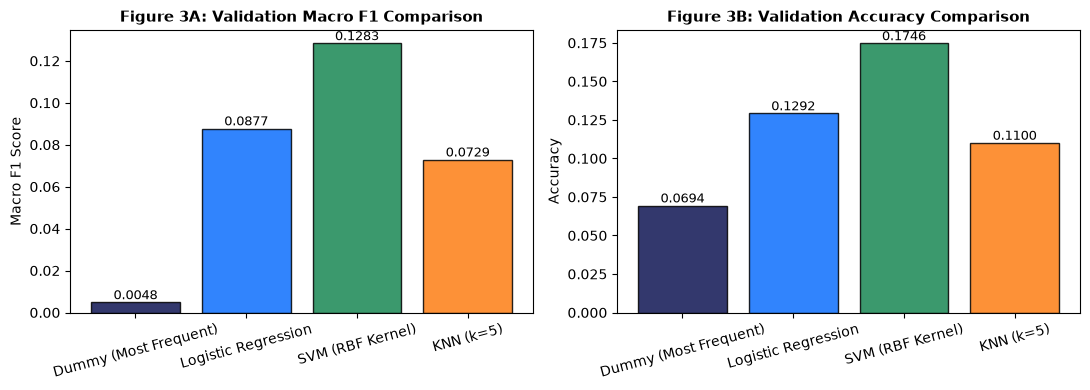

In [12]:
# Figure 3: Baseline Performance Comparison Bar Chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
colors = ["#0f1554", "#0d6efd", "#198754", "#fd7e14"]

bars1 = ax1.bar(results_df["Model"], results_df["Val Macro F1"], color=colors, edgecolor="black", alpha=0.85)
ax1.set_title("Figure 3A: Validation Macro F1 Comparison", fontsize = 11, fontweight="bold")
ax1.set_ylabel("Macro F1 Score")
ax1.tick_params(axis='x', rotation=15)
for bar in bars1:
    yval = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0001, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

bars2 = ax2.bar(results_df["Model"], results_df["Val Accuracy"], color=colors, edgecolor="black", alpha=0.85)
ax2.set_title("Figure 3B: Validation Accuracy Comparison", fontsize=11, fontweight="bold")
ax2.set_ylabel("Accuracy")
ax2.tick_params(axis='x', rotation=15)
for bar in bars2:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0001, f"{yval:.4f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### Part 4: Conclusions & Risks

### Conclusions from Stage 1:
1. Demonstrated Learning Above Chance Floor: All classical models beat the Dummy majority baseline (Macro F1 = 0.0048, Accuracy = 6.87%). The SVM with RBF Kernel achieves the strongest validation performance (17.54% accuracy, 0.1290 Macro F1, representing an absolute gain of +0.1243 over the dummy baseline).
2. Underfitting on raw pixels: The best model reaches only about 17.5% validation accuracy. Each image is shrunk to 32 × 32 and flattened into one long vector, so the models lose which pixels were next to each other. A disease spot in a different part of the image looks like completely different input. Small details such as lesions are also mostly lost at 32 × 32.

### Risks for Next Stages:
1. Background Memorization Bias: Stock images with plain white backdrops versus outdoor field photos with soil may cause pixel-level models to memorize background illumination rather than leaf pathology.
2. Severe Class Imbalance: Extreme category frequency differences hinder generalization on rare disease classes.
3. Stage 2 & 3 Roadmap: In Stage 2 (Lab 8), we will test tree-based ensembles (Random Forest, XGBoost) and MLPs with hyperparameter tuning on validation data. In Stage 3 (Lab 11), we will train a Convolutional Neural Network (CNN), which looks at small neighbouring pixel regions and can detect the same pattern wherever it appears in the image.

## Stage 2: Tree-Based Models and Neural Network

### Evaluation Protocol

All stage 2 models use exactly the same inputs as the Stage 1 baselines:

- The same retained training and validation images (3384 / 422).

- The same 32 x 32 x 3 = 3072 pixel features, standardized with the scaler fitted on training data only.

- The same metrics: validation accuracy, macro-F1 (primary), macro recall and macro precision

- The same random seed (42)


The test set is not used anywhere in Stage 2.


For each model the number of parameters, training time and time per image are reported.

For tree-based models, "parameters" means the total number of tree nodes, since trees store split rules rather than weights

### Hyperparameter search plan

- Method: Grid Search, every combination in the grid is trained on the training split and scored on the validation split.

- Objective: Validation macro-F1.

- Budget: At most 12 configurations per model.

- Stopping Rule: Every configuration in the grid is evaluated once, no extra configurations are added after seeing results. The MLP also uses early stopping on a 10% slice held out from the training split.

- Selection: The configuration with the highest validation macro-F1 is chosen for each model, and the model with the highest validation macro-F1 overall becomes the Stage 2 finalist.

| Model | Hyperparameters Searched | Number of Configurations |
|-------|--------------------------|--------------------------|
| XGBoost |  | |
| AdaBoost | | |
| Random Forest | | |
| MLP | | |

In [13]:
# Stage 2 shared evaluation framework
import time
import pandas as pd
from sklearn.model_selection import ParameterGrid
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

SEED = 42

# Convert class names to integers (XGBoost needs integer labels)
label_encoder = LabelEncoder()
label_encoder.fit(y_train)
y_train_enc = label_encoder.transform(y_train)
y_val_enc = label_encoder.transform(y_val)
print("Classes in training data:", len(label_encoder.classes_))


def count_params(model):
    """Number of learned values: weights for LR/SVM/MLP, tree nodes for tree models."""
    total = 0

    # Multi Layer Perceptron
    if hasattr(model, "coefs_"):
        for weights in model.coefs_:
            total += weights.size
        for biases in model.intercepts_:
            total += biases.size

    # Logistic Regression
    elif hasattr(model, "coef_"):
        total = model.coef_.size + model.intercept_.size

    elif hasattr(model, "support_vectors_"): # SVM
        total = model.support_vectors_.size + model.dual_coef_.size + model.intercept_.size

    # XGBoost
    elif hasattr(model, "get_booster"):
        total = len(model.get_booster().trees_to_dataframe())

    # Random Forest, AdaBoost
    elif hasattr(model, "estimators_"):
        for tree in model.estimators_:
            total += tree.tree_.node_count

    # Dummy and KNN stay at 0
    return total


trials = [] # one row for every configuration tried
results = [] # one row per model: its best configuration
best_models = {} # the fitted best model for each model name


def evaluate(model, name, params):
    """Train on the training split, score on the validation split, save one row."""
    start = time.perf_counter()
    model.fit(X_train_scaled, y_train_enc)
    train_time = time.perf_counter() - start

    start = time.perf_counter()
    preds = model.predict(X_val_scaled)
    infer_time = time.perf_counter() - start

    row = {
        "Model": name,
        "Params": str(params),
        "Val Accuracy": accuracy_score(y_val_enc, preds),
        "Val Macro F1": f1_score(y_val_enc, preds, average="macro", zero_division=0),
        "Val Macro Recall": recall_score(y_val_enc, preds, average="macro", zero_division=0),
        "Val Macro Precision": precision_score(y_val_enc, preds, average="macro", zero_division=0),
        "Parameters": count_params(model),
        "Train Time (s)": train_time,
        "Infer Latency (ms/img)": 1000 * infer_time / len(y_val_enc),
    }
    trials.append(row)
    return model, row


def run_grid(name, make_model, grid):
    """Try every configuration in the grid and keep the one with the best validation macro-F1."""
    best_model = None
    best_row = None

    for params in ParameterGrid(grid):
        model, row = evaluate(make_model(**params), name, params)
        print(f"{name} {params}: macro-F1 = {row['Val Macro F1']:.4f}")

        if best_row is None or row["Val Macro F1"] > best_row["Val Macro F1"]:
            best_model, best_row = model, row

    results.append(best_row)
    best_models[name] = best_model
    print(f"Best {name}: {best_row['Params']} (macro-F1 = {best_row['Val Macro F1']:.4f})")
    return best_model, best_row


# Re-run the Stage 1 baselines through the same framework so they are scored the same way
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

baselines = {
    "Dummy (Most Frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter = 1000, C = 0.01, random_state=SEED),
    "SVM (RBF Kernel)": SVC(C=10, random_state=SEED),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

for name in baselines:
    model = baselines[name]
    fitted, row = evaluate(model, name, {})
    results.append(row)
    best_models[name] = fitted

display(pd.DataFrame(results).round(4))

Classes in training data: 27


,Model,Params,Val Accuracy,Val Macro F1,Val Macro Recall,Val Macro Precision,Parameters,Train Time (s),Infer Latency (ms/img)
0,Dummy (Most Frequent),{},0.0694,0.0048,0.0370,0.0026,0,0.0369,0.0004
1,Logistic Regression,{},0.1292,0.0877,0.1021,0.1058,82971,71.9155,0.0082
2,SVM (RBF Kernel),{},0.1746,0.1283,0.1538,0.1599,10381749,37.6545,12.6796
3,KNN (k=5),{},0.1100,0.0729,0.0897,0.0793,0,0.0131,0.6421


In [14]:
# ===== MLP (owner: Luca) =====
import torch
from torch import nn


class TorchMLP:
    """A one-hidden-layer MLP built like Lab 7, with fit() and predict() so run_grid can use it."""

    def __init__(self, hidden_units, weight_decay, epochs=30, X_val=None, y_val=None):
        self.hidden_units = hidden_units
        self.weight_decay = weight_decay
        self.epochs = epochs
        self.X_val = X_val      # only used to draw the learning curve, never to choose settings
        self.y_val = y_val

    def fit(self, X, y):
        torch.manual_seed(SEED)
        X = torch.tensor(X, dtype=torch.float32)
        y = torch.tensor(y, dtype=torch.long)
        n_classes = int(y.max()) + 1

        # Network: inputs -> hidden layer with ReLU -> one score per class
        self.network = nn.Sequential(
            nn.Linear(X.shape[1], self.hidden_units),
            nn.ReLU(),
            nn.Linear(self.hidden_units, n_classes),
        )
        optimizer = torch.optim.Adam(self.network.parameters(), lr=0.001, weight_decay=self.weight_decay)
        loss_fn = nn.CrossEntropyLoss()
        batches = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X, y), batch_size=64, shuffle=True)

        self.train_loss = []
        self.val_loss = []
        for epoch in range(self.epochs):
            # Training: one pass over all mini-batches
            self.network.train()
            for xb, yb in batches:
                optimizer.zero_grad()                     # clear old gradients
                loss = loss_fn(self.network(xb), yb)      # forward pass + loss
                loss.backward()                           # backpropagation
                optimizer.step()                          # update the weights

            # Record losses after each epoch for the learning curve
            self.network.eval()
            with torch.no_grad():
                self.train_loss.append(loss_fn(self.network(X), y).item())
                if self.X_val is not None:
                    X_v = torch.tensor(self.X_val, dtype=torch.float32)
                    y_v = torch.tensor(self.y_val, dtype=torch.long)
                    self.val_loss.append(loss_fn(self.network(X_v), y_v).item())
        return self

    def predict(self, X):
        self.network.eval()
        with torch.no_grad():
            scores = self.network(torch.tensor(X, dtype=torch.float32))
        return scores.argmax(dim=1).numpy()      # class with the highest score


mlp_grid = {
    "hidden_units": [64, 128],
    "weight_decay": [0.0, 0.001, 0.01],
}   # 2 x 3 = 6 configurations

best_mlp, best_mlp_row = run_grid(
    "MLP",
    lambda **p: TorchMLP(X_val=X_val_scaled, y_val=y_val_enc, **p),
    mlp_grid,
)

MLP {'hidden_units': 64, 'weight_decay': 0.0}: macro-F1 = 0.1024
MLP {'hidden_units': 64, 'weight_decay': 0.001}: macro-F1 = 0.0920
MLP {'hidden_units': 64, 'weight_decay': 0.01}: macro-F1 = 0.0900
MLP {'hidden_units': 128, 'weight_decay': 0.0}: macro-F1 = 0.1152
MLP {'hidden_units': 128, 'weight_decay': 0.001}: macro-F1 = 0.1127
MLP {'hidden_units': 128, 'weight_decay': 0.01}: macro-F1 = 0.0862
Best MLP: {'hidden_units': 128, 'weight_decay': 0.0} (macro-F1 = 0.1152)


Training accuracy: 0.9908 | Validation accuracy: 0.1483


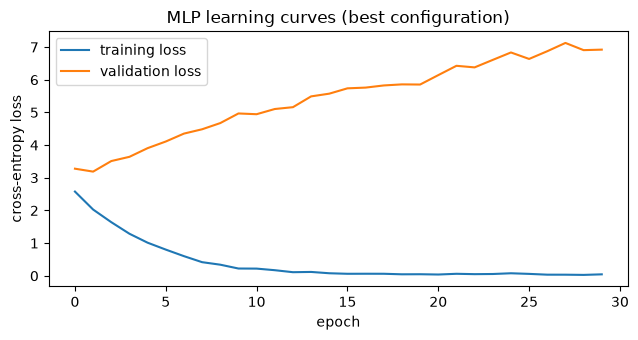

In [15]:
import matplotlib.pyplot as plt

# Overfitting check: compare accuracy on the training data with accuracy on the validation data
train_acc = (best_mlp.predict(X_train_scaled) == y_train_enc).mean()
print(f"Training accuracy: {train_acc:.4f} | Validation accuracy: {best_mlp_row['Val Accuracy']:.4f}")

# Learning curves (like Lab 7): if validation loss rises while training loss falls, the model is overfitting
plt.figure(figsize=(6.5, 3.5))
plt.plot(best_mlp.train_loss, label="training loss")
plt.plot(best_mlp.val_loss, label="validation loss")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("MLP learning curves (best configuration)")
plt.legend()
plt.tight_layout()
plt.show()

### MLP: results
We used a PyTorch MLP with one ReLU hidden layer, trained for 30 epochs with Adam (learning rate 0.001, batches of 64)
and cross-entropy loss, as in Lab 7. We searched the hidden layer width (64, 128) and L2 weight decay (0, 0.001, 0.01).
The validation loss is only recorded for the learning curve; configurations are compared by validation macro-F1 through run_grid.

<Which configuration won and its validation macro-F1. How does it compare to the SVM baseline (macro-F1 0.1290)?>

<Training vs validation accuracy and the learning curves: is the model overfitting? Why might that happen with flattened pixels?>

Colour-histogram inputs were also explored and are kept for the Stage 3 additional analysis.